# Lab 2: Belt

In [424]:
# Pulley - Class 2

# Import statements
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import math

import MechDesign.Helpers as HM

from MechDesign.Units.Units import m_, mm_, kg_, s_, N_, rpm_, W_, deg_, mu_m_, dm_
import MechDesign.Units.UnitMethods as UM

import MechDesign.RnM as RnM

**Problem description**

The drive of a gearbox is to be designed as a *narrow profile V-belt* according to the requirements of the lab asignment. The chosen three-phase motor 160L has a drive power $P_{motor}= 15kW$ at a speed of $n=1500rpm$.

Motor selection: 

- $P_{Motor} = 15.0\text{ kW}$
- $\eta = 0.90$
- $K_A = 1.35$


Ratio calculation: 
- $i_g = 4.089$
- $i_b = 2.454$
- $i_{total} = 10.03$



The calculation is carried out according to the flowchart shown in Figure 16-18

---

### Determining the type of belt

Narrow DIN 2211 profile V-belt as specified of the lab assignment

### Determining disc diameters

According to the table 16-21 corresponding **minimum** driving pulley diameter for the asynchronous motor is $D_{dk} = 140mm$.  To determine the driving pulley diameter the $P/n$ ratio is evualuted as following.  
$$P/n = 15kW/1500 min^{-1} = 0.01 kW*min $$


According to the table 16-7, diameter of the smallest pulley diameter is $D_{dk}=160mm$ 

In [425]:
# Defining the belt to be calculated
BT = RnM.Belt()     #--- since Belt is part of the RnM library we call it as a part of it ---

BT.d_dg = BT.E16_20A_LargeDiskDiameter()

HM.EqPrint('d_dg',BT.d_dg)
HM.MyHelp(BT.d_dg)

BT.d_dk = 160*mm_
BT.i = 2.454

d_dg = HM.substitute(BT.d_dg ,BT) 
HM.EqPrint('d_dg', d_dg)  
t=0

Eq(d_dg, _d_dk*_i)

_d_dk*_i

    i : [] transmission ratio (equivalent to gear ratio in case of gears)
    d_dk : [mm] reference diameter of smaller disk, note explenation equation 16-36


Eq(d_dg, 392.6*mm_)




- $d_{dg} = 400mm$
- $d_{dk} = 160mm$

---


## Center Distance $e$ and Belt Length $L_d$


Center distance formula for V- and poly- V- belts according to equation 16.21 of the book: 
$$0.7 \cdot (d_g + d_k) \le e' \le 2 \cdot (d_g + d_k) $$


In [426]:
# equations for the limits of the center distance

BT.eprime_LL = BT.E16_21A_ShaftDistanceLowerLimit()
BT.eprime_UL = BT.E16_21_ShaftDistanceUpperLimit()
BT.Lprime = BT.E16_23_TheoreticalBeltLength()

In [427]:
BT.d_dg = 400 * mm_  #--- diameter of the driven pulley ---
BT.d_dk = 160 * mm_  #--- diameter of the driving pulley - --


eprime_LL = HM.substitute(BT.eprime_LL,BT) 
eprime_UL = HM.substitute(BT.eprime_UL,BT)
Lprime = HM.substitute(BT.Lprime,BT)
HM.EqPrint('eprime_LL',eprime_LL) 
HM.EqPrint('eprime_UL',eprime_UL)
t=0


Eq(eprime_LL, 386.8*mm_)

Eq(eprime_UL, 1105.0*mm_)

In [428]:
BT.L_d = 2500*mm_  #--- belt length ---
BT.e = BT.E16_22_FinalShaftDistance().evalf()

BT.e = UM.RemoveUnits(BT.e)  *mm_    #this will first remove the units and then add mm again, avoiding the mm**1
HM.EqPrint('e',BT.e)
t=0

Eq(e, 801.2*mm_)

 According to DIN 323 R40, belt length is chosen.
 



- $D_{dk} = 160mm$
- $D_{dg} = 400mm$
-  $e = 801mm$
- $L = 2500mm$


---

## Calculation for wrap angle

The wrap angle $B_k$ together with the coefficient of friction $\mu$ determines to the efficiency and the useful force transmission.
 
 => Large wrap angles require lower contact pressure thus a lower shaft load.

In [429]:
BT.beta_k = BT.E16_24A_circumfranceAngle()
HM.EqPrint('beta_k',(BT.beta_k)/3.14*180*deg_)
HM.EqPrint('beta_k',BT.beta_k)
t=0

Eq(beta_k, 162.9*deg_)

Eq(beta_k, 2.841)

## Calculation for number of belts



Formula 16.28 for required number of V-belts or ribs: 

$$ z \ge \frac{P'}{(P_N + U_z) \cdot c_1 \cdot c_2} = \frac{K_A \cdot P_{\text{nom}}}{(P_N + U_z) \cdot c_1 \cdot c_2} $$


* **$K_A$**: Operating factor to consider the dynamic operating conditions; if no factory data is available, values according to table 3-5
* *$P_{\text{nom}}$**: The rated power to be transmitted by the V-belt drive
* **$P_N$**: The nominal power to be transmitted by one V-belt or one rib; values according to table 16-15
* **$U_z$**: Transfer surcharge for $i > 1$; values according to table 16-16
* **$c_1$**: Angle factor; values for $\beta_1 \le 180^\circ$ according to table 16-17
* **$c_2$**: Length factor that takes into account the power change when the actual target length $L_d$ differs from the 'reference belt length'; values according to table 16-17



In [430]:


BT.P = 8000*W_
BT.K_A = 1.5

BT.P_N = 4600*W_  # table 16-15b  1500rpm and 160mm diameters
BT.U_z = 210*W_   # table 16-16b, 1500rpm and i=2.454
BT.c_1 = 0.9     # table 16-17a  beta_K 162.78°
BT.c_2 = 1.085     # table 16-17c SPZ 2500mm belt,


BT.Pprime = BT.P * BT.K_A
BT.z = BT.E16_29_NumberOfBelts()



HM.EqPrint('z',BT.z)
t=0

Eq(z, 2.555)

## Circumferential force, belt speed, bending frequency 




In [431]:
BT.n = 1500*rpm_
BT.zz = 2


BT.v = UM.All_to_SI( BT.d_dk/2*BT.n)
BT.F_t =  BT.E16_27_FrictionForce()


HM.EqPrint('v',BT.v)
HM.EqPrint('F_t',UM.kgm_s2_to_N( UM.All_to_SI(BT.F_t)))

BT.f_B =UM.All_to_SI( BT.E16_37_BendingFrequency())
t=HM.EqPrint('f_B',BT.f_B)
t=0

Eq(v, 12.57*m_/s_)

Eq(F_t, 954.9*N_)

Eq(f_B, 10.05/s_)

Groove angle ($\alpha$) for narrow V-belt pulleys (profiles SPZ, SPA, SPB, SPC) is selected from table 16.13 

$$F_a = \frac{F_t \sqrt{m^2 + 1 - 2m \cos(\beta_1)}}{m - 1}$$




In [432]:
BT.mu = 0.4
BT.n_1 = BT.n
BT.beta_1 = BT.beta_k   
BT.alpha = UM.All_to_SI( 38*deg_)
BT.z = 3
BT.A_S = 55.6*mm_*mm_

BT.rho =  1.3*kg_/(dm_*dm_*dm_)


T  = UM.kgm_s2_to_N( UM.All_to_SI( BT.Pprime / BT.n_1))
HM.EqPrint('T',T)
BT.F_t = BT.Pprime / BT.v
HM.EqPrint('F_t',UM.kgm_s2_to_N( UM.All_to_SI(BT.F_t)))
BT.muprime = BT.E16_1B_Set2muprime()
BT.mu = BT.muprime
HM.EqPrint('mu',BT.mu)
BT.m = BT.E16_3_Eytelwein()
HM.EqPrint('m',BT.m)
BT.F_a = UM.kgm_s2_to_N( UM.All_to_SI(BT.E16_6_AxleLoad()))
t=HM.EqPrint('F_a',BT.F_a)

BT.F_c = UM.kgm_s2_to_N( UM.All_to_SI( BT.z*BT.E16_5_CentrifugalForce())) 

#UM.kgm_s2_to_N( UM.All_to_SI(BT.z*BT.E16_5_CentrifugalForce())) 
t=HM.EqPrint('F_c', BT.F_c)


Eq(T, 76.39*N_*m_)

Eq(F_t, 954.9*N_)

Eq(mu, 1.229)

Eq(m, 32.8)

Eq(F_a, 1014.0*N_)

Eq(F_c, 0.03424*N_)

---

# Graphs




In [433]:
B = RnM.Belt()
BF = RnM.Belt()


""" f_B = v * zz / L_d """

<>:53: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\m'
C:\Users\tseen\AppData\Local\Temp\ipykernel_17876\147843055.py:53: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title('Static Axial load $(F_{a0})$ vs friction coefficient $(\mu)$ for different pulley diameters')


Eq(F_a0, 1.337*_d_w**2*kg_/m_ + 169.8*N_*m_*(1.91*exp(8.726*_mu) + exp(17.45*_mu) + 1.0)**0.5/(_d_w*s_*(exp(8.726*_mu) - 1.0)))

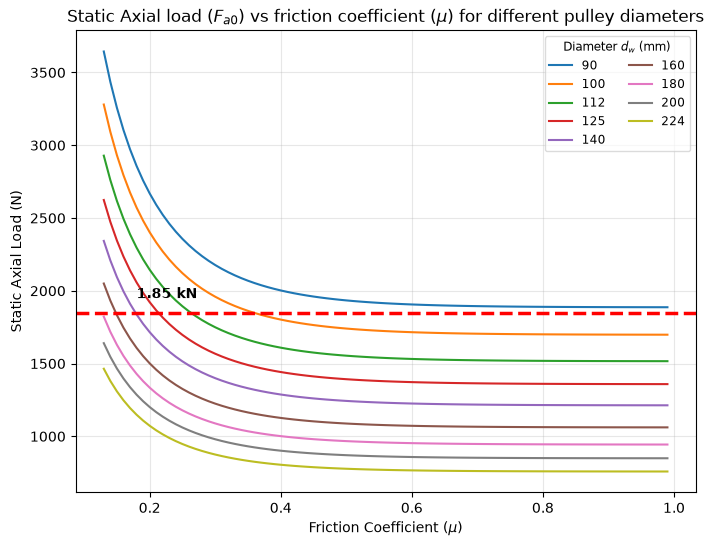

In [434]:
B.K_A = 1.5
B.beta_1 = 2.841
B.eta = 0.9 
B.P = 8000*W_
#B.d_w = 160*mm_
B.n = 25 # rev/s
B.alpha = UM.All_to_SI( 38*deg_)
B.rho = 1.3*kg_/(dm_*dm_*dm_)
B.A_S = 55.56*mm_*mm_
B.z = 3

B.v = B.E16_36_BeltSpeed()

B.muprime = B.E16_1B_Set2muprime()
B.mu = B.muprime

B.m = B.E16_3_Eytelwein()
B.Pprime = B.P*B.K_A/B.eta
B.F_t = B.Pprime / B.v   


B.F_c = B.z*B.E16_5_CentrifugalForce() 
B.F_a = B.E16_6_AxleLoad()
B.F_a0 = UM.kgm_s2_to_N( UM.All_to_SI( B.E16_7_TotalAxleLoad()))
t=HM.EqPrint('F_a0',B.F_a0)





# 1. Convert mm to meters as pure numerical floats (divide by 1000)
diameter_mm = [90, 100, 112, 125, 140, 160, 180, 200, 224]
diameter_vals = [d / 1000.0 for d in diameter_mm]  # Pure numbers in meters

mu_vals = np.arange(0.13, 1.0, 0.01)

# Evaluate axle load

F_a0_vals, A, C = HM.evaluate(B.F_a0, {'d_w': diameter_vals, 'mu': mu_vals})




fig, ax = plt.subplots(figsize=(8, 6))


lines = ax.plot(mu_vals, F_a0_vals.T)

ax.legend(lines, diameter_mm, title=r'Diameter $d_w$ (mm)',
          loc='upper right', ncol=2, fontsize='small', title_fontsize='small',
          framealpha=0.7)

ax.set_title('Static Axial load $(F_{a0})$ vs friction coefficient $(\mu)$ for different pulley diameters')
ax.set_xlabel(r'Friction Coefficient ($\mu$)')
ax.set_ylabel('Static Axial Load (N)')
ax.axhline(1850, color='red', linestyle='--', linewidth=2.5)
ax.text(0.18, 1950, '1.85 kN', fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()




In [436]:
# B.F_c = B.z * 0.07223 * (B.v**2)

# z_vals = [3, 4, 5]

# v_vals = np.arange(1, 25, 0.01)

# # Evaluate axle load

# F_c_vals, A, C = HM.evaluate(B.F_c, {'z': z_vals, 'v': v_vals})




# fig, ax = plt.subplots(figsize=(8, 6))


# lines = ax.plot(v_vals, F_c_vals.T)
# ax.set_title('Centrifugal Force ($F_c$) vs. Belt Speed ($v$) for different number of Belts')
# ax.set_xlabel(r'Belt Speed (m/s)')
# ax.set_ylabel(r'Centrifugal Force (N)')

# yy_point = 34.24


# ax.plot([0, 12.57, 12.57], [yy_point, yy_point, 0], color='r', linestyle='--')

# ax.legend([f'z = {z}' for z in z_vals])

# ax.annotate(f'$F_{{c}}$ = {yy_point} N', xy=(0, 0), xytext=(1, yy_point + 2),
#             bbox=dict(facecolor='white', edgecolor='none'), xycoords='data', size=11)

# plt.grid(True, alpha=0.3)
# plt.show()

